# Machine Learning — Notebook 13
## Gradient Boosting & XGBoost

**Program:** Data Science & Artificial Intelligence  
**Business Case:** AdventureWorks — Return Risk Intelligence  
**Focus:** Ensemble learning, gradient boosting, XGBoost, model evaluation and interpretation

---

### Learning outcomes

By the end of this notebook, you will be able to:

1. Explain the difference between bagging and boosting.
2. Describe how gradient boosting builds an ensemble of trees sequentially.
3. Explain the roles of learning rate, number of estimators and tree complexity.
4. Train and evaluate a Gradient Boosting model with scikit-learn.
5. Train and tune an XGBoost classifier.
6. Compare models using cross-validation and classification metrics.
7. Interpret feature importance and communicate model limitations.

**Working standard:** Keep the test set separate until final evaluation. All model selection must use training data only.

## Contents

1. Business problem and dataset
2. Ensemble learning: bagging and boosting
3. Gradient boosting intuition
4. Train a scikit-learn Gradient Boosting model
5. Understand boosting hyperparameters
6. Monitor learning and diagnose overfitting
7. XGBoost: concepts and implementation
8. Model comparison and cross-validation
9. Feature importance and interpretation
10. Mini project: return-risk model selection
11. Knowledge check and readiness review

## 1. Set up the environment

We use pandas for tabular data, NumPy for reproducible data generation, Matplotlib and Seaborn for visualization, and scikit-learn and XGBoost for modeling.

If you are using Google Colab and XGBoost is not installed, run the installation command below.

In [1]:
# If needed in a fresh environment, uncomment:
# %pip install -q xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier

from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Environment ready.")

Environment ready.


## 2. Define the business problem

AdventureWorks wants to identify orders that have a high probability of being returned. The operations team can use risk scores to prioritize manual checks and improve customer experience.

The target column is `return_risk`:

- `1`: the order is considered high risk.
- `0`: the order is considered normal risk.

The model receives information available at the time the order is placed. Do not use information that becomes available only after delivery or after a return has occurred. This is an important control against **target leakage**.

### Dataset design

The dataset contains a focused set of operational signals:

| Feature | Meaning |
|---|---|
| `order_value` | Total order value in currency units |
| `items_count` | Number of items in the order |
| `discount_rate` | Discount applied to the order |
| `delivery_days` | Estimated delivery time at checkout |
| `customer_orders` | Number of previous orders |
| `customer_return_rate` | Historical return rate before this order |
| `is_express_shipping` | Whether express shipping was selected |
| `category_encoded` | Numeric category code |

The target is generated from a transparent synthetic risk process. It is suitable for learning workflows, not for making real operational decisions.

## 3. Create a reproducible AdventureWorks dataset

A fixed random seed makes the example reproducible. The features are designed to have plausible relationships with return risk, while retaining enough randomness to avoid a perfectly predictable target.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_samples = 2400

order_value = np.clip(rng.gamma(shape=2.2, scale=65, size=n_samples), 15, 650)
items_count = rng.integers(1, 9, size=n_samples)
discount_rate = rng.choice([0.00, 0.05, 0.10, 0.15, 0.20, 0.25], size=n_samples,
                           p=[0.22, 0.16, 0.22, 0.18, 0.14, 0.08])
delivery_days = rng.integers(1, 9, size=n_samples)
customer_orders = rng.integers(1, 45, size=n_samples)
customer_return_rate = np.clip(rng.beta(2.0, 12.0, size=n_samples), 0, 0.85)
is_express_shipping = rng.binomial(1, 0.28, size=n_samples)
category_encoded = rng.integers(0, 5, size=n_samples)

logit = (
    -2.65
    + 0.0030 * order_value
    + 0.13 * items_count
    + 2.0 * discount_rate
    + 0.075 * delivery_days
    - 0.018 * customer_orders
    + 3.0 * customer_return_rate
    - 0.28 * is_express_shipping
    + np.select([category_encoded == 1, category_encoded == 3], [0.25, 0.45], default=0.0)
)
probability = 1 / (1 + np.exp(-logit))
return_risk = rng.binomial(1, probability)

orders = pd.DataFrame({
    "order_value": order_value.round(2),
    "items_count": items_count,
    "discount_rate": discount_rate,
    "delivery_days": delivery_days,
    "customer_orders": customer_orders,
    "customer_return_rate": customer_return_rate.round(3),
    "is_express_shipping": is_express_shipping,
    "category_encoded": category_encoded,
    "return_risk": return_risk
})

orders.head()

,order_value,items_count,discount_rate,delivery_days,customer_orders,customer_return_rate,is_express_shipping,category_encoded,return_risk
0,150.46,8,0.0,2,20,0.288,0,2,1
1,200.93,6,0.0,8,8,0.212,1,3,0
2,133.04,8,0.1,6,15,0.094,0,2,1
3,119.85,6,0.0,1,28,0.226,0,2,1
4,217.38,5,0.0,2,13,0.087,0,1,0


### Inspect the data before modeling

A reliable modeling workflow starts with data inspection. Confirm the dimensions, data types, missing values, target distribution and basic numeric ranges.

In [3]:
print(f"Rows: {orders.shape[0]:,}")
print(f"Columns: {orders.shape[1]}")
print(f"High-risk order rate: {orders['return_risk'].mean():.1%}")

display(orders.head())
display(orders.describe().T)
display(orders.isna().sum().to_frame("missing_values"))

Rows: 2,400
Columns: 9
High-risk order rate: 29.8%


,order_value,items_count,discount_rate,delivery_days,customer_orders,customer_return_rate,is_express_shipping,category_encoded,return_risk
0,150.46,8,0.0,2,20,0.288,0,2,1
1,200.93,6,0.0,8,8,0.212,1,3,0
2,133.04,8,0.1,6,15,0.094,0,2,1
3,119.85,6,0.0,1,28,0.226,0,2,1
4,217.38,5,0.0,2,13,0.087,0,1,0


,count,mean,std,min,25%,50%,75%,max
order_value,2400.0,143.671929,96.602078,15.000,72.7175,124.985,188.41000,650.000
items_count,2400.0,4.474583,2.286343,1.000,2.0000,5.000,6.00000,8.000
discount_rate,2400.0,0.106479,0.078496,0.000,0.0500,0.100,0.15000,0.250
delivery_days,2400.0,4.419583,2.292718,1.000,2.0000,4.000,6.00000,8.000
customer_orders,2400.0,22.402083,12.643655,1.000,11.0000,23.000,33.00000,44.000
customer_return_rate,2400.0,0.142863,0.092561,0.004,0.0720,0.124,0.19525,0.632
is_express_shipping,2400.0,0.298750,0.457805,0.000,0.0000,0.000,1.00000,1.000
category_encoded,2400.0,1.958333,1.387107,0.000,1.0000,2.000,3.00000,4.000
return_risk,2400.0,0.297500,0.457254,0.000,0.0000,0.000,1.00000,1.000


,missing_values
order_value,0
items_count,0
discount_rate,0
delivery_days,0
customer_orders,0
customer_return_rate,0
is_express_shipping,0
category_encoded,0
return_risk,0


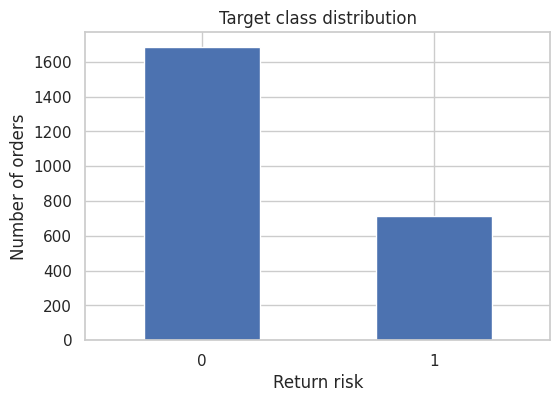

In [4]:
ax = orders["return_risk"].value_counts().sort_index().plot(
    kind="bar", rot=0, figsize=(6, 4), title="Target class distribution"
)
ax.set_xlabel("Return risk")
ax.set_ylabel("Number of orders")
plt.show()

### Separate features and target

`X` contains the input features. `y` contains the value the model must learn to predict.

We create the test split now and keep it untouched during model development. Stratification preserves approximately the same target-class proportion in both subsets.

In [5]:
FEATURES = [
    "order_value", "items_count", "discount_rate", "delivery_days",
    "customer_orders", "customer_return_rate", "is_express_shipping",
    "category_encoded"
]
TARGET = "return_risk"

X = orders[FEATURES]
y = orders[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training positive rate:", round(y_train.mean(), 3))
print("Test positive rate:", round(y_test.mean(), 3))

Training set: (1920, 8)
Test set: (480, 8)
Training positive rate: 0.297
Test positive rate: 0.298


## 4. Ensemble learning: from one model to many

An **ensemble** combines predictions from multiple models. The goal is to produce a stronger or more stable predictor than a single model.

Two important ensemble strategies are:

- **Bagging:** train models independently, often on different bootstrap samples, then combine their predictions. Random Forest is a common example.
- **Boosting:** train models sequentially. Each new learner focuses on reducing errors made by the current ensemble.

Gradient Boosting is a boosting method that adds decision trees in stages. Each new tree is fitted to information derived from the current model's errors.

### Bagging versus boosting

| Aspect | Bagging | Boosting |
|---|---|---|
| Training | Models are largely independent | Models are added sequentially |
| Main idea | Reduce variance through aggregation | Improve the model stage by stage |
| Example | Random Forest | Gradient Boosting, XGBoost |
| Sensitivity | Often robust to noise | Can overfit if complexity is not controlled |

**Important:** Boosting is not automatically better than bagging. Performance depends on the dataset, validation strategy, tuning and business objective.

### Check your understanding

**Exercise 1**

In your own words, explain why boosting trains learners sequentially. Then identify one situation where a Random Forest may be a sensible baseline before trying boosting.

*Instructor discussion:* Look for an explanation that connects sequential learning to correcting the current ensemble's errors, and recognizes the value of a strong, low-maintenance baseline.

## 5. Gradient Boosting intuition

Gradient Boosting builds an additive model:

1. Start with an initial prediction.
2. Measure how poorly the current model performs using a loss function.
3. Fit a small decision tree to the negative gradient of that loss.
4. Add the new tree's contribution to the ensemble.
5. Repeat for a specified number of boosting stages.

For classification, scikit-learn's `GradientBoostingClassifier` optimizes a differentiable loss, commonly log loss. The trees are regression trees that contribute to the model's prediction scores.

### The role of a learning rate

Each new tree contributes only part of its proposed correction. The `learning_rate` controls the size of that contribution.

- A smaller learning rate makes each update more conservative.
- A larger learning rate makes each update stronger.
- Smaller learning rates often require more trees.

The learning rate and number of estimators should be considered together. There is no universally best combination.

### A conceptual example

Imagine the current model underestimates return risk for a group of orders. The next tree learns a correction for patterns associated with those errors. The ensemble adds this correction to its existing predictions.

The next tree does not simply replace the previous tree. The model is the combined contribution of all boosting stages.

## 6. Train a Gradient Boosting classifier

We begin with a controlled baseline. Tree-based Gradient Boosting does not require feature scaling in the same way that distance-based models such as KNN do.

In [6]:
gb_model = GradientBoostingClassifier(
    n_estimators=120,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=12,
    random_state=RANDOM_STATE
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)
gb_proba = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting baseline")
print("Accuracy :", round(accuracy_score(y_test, gb_pred), 3))
print("Precision:", round(precision_score(y_test, gb_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, gb_pred, zero_division=0), 3))
print("F1       :", round(f1_score(y_test, gb_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, gb_proba), 3))

Gradient Boosting baseline
Accuracy : 0.698
Precision: 0.464
Recall   : 0.091
F1       : 0.152
ROC-AUC  : 0.63


### Interpret the metrics in the business context

- **Precision:** among orders flagged as high risk, how many were actually high risk?
- **Recall:** among all high-risk orders, how many did the model identify?
- **F1-score:** the harmonic mean of precision and recall.
- **ROC-AUC:** how well the model ranks positive cases above negative cases across thresholds.

For an operational review process, missing a genuinely high-risk order may be more costly than reviewing an order that turns out to be normal. This may make recall important, but the final threshold should reflect review capacity and business costs.

### Exercise 2 — First Gradient Boosting model

1. Change `n_estimators` from 120 to 200.
2. Keep the other parameters unchanged.
3. Refit the model and compare F1 and ROC-AUC.
4. Explain why adding more trees does not guarantee better test performance.

Do not repeatedly tune against the test set. This is a guided demonstration; later tuning should use cross-validation on the training data.

## 7. Understand the main Gradient Boosting parameters

| Parameter | Meaning | Typical effect |
|---|---|---|
| `n_estimators` | Number of boosting stages | More stages increase capacity and training time |
| `learning_rate` | Contribution of each stage | Smaller values make updates more conservative |
| `max_depth` | Maximum depth of each tree | Deeper trees capture more complex interactions |
| `min_samples_leaf` | Minimum samples required at a leaf | Larger values can make trees smoother |
| `subsample` | Fraction of training rows used per stage | Values below 1 introduce stochasticity |
| `max_features` | Number or fraction of features considered | Can reduce correlation and model complexity |

A useful starting point is to use shallow trees and tune learning rate and number of estimators together.

### Compare learning-rate and estimator combinations

The following experiment uses a validation split taken only from the training data. The test set remains untouched.

In [7]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train
)

experiments = []
for rate, trees in [(0.02, 300), (0.05, 150), (0.10, 100), (0.20, 60)]:
    model = GradientBoostingClassifier(
        learning_rate=rate, n_estimators=trees, max_depth=2,
        min_samples_leaf=12, random_state=RANDOM_STATE
    )
    model.fit(X_fit, y_fit)
    valid_prob = model.predict_proba(X_valid)[:, 1]
    experiments.append({
        "learning_rate": rate,
        "n_estimators": trees,
        "validation_roc_auc": roc_auc_score(y_valid, valid_prob),
        "validation_f1": f1_score(y_valid, model.predict(X_valid), zero_division=0)
    })

pd.DataFrame(experiments).sort_values("validation_roc_auc", ascending=False)

,learning_rate,n_estimators,validation_roc_auc,validation_f1
3,0.20,60,0.719885,0.287234
2,0.10,100,0.713671,0.267380
1,0.05,150,0.710060,0.231214
0,0.02,300,0.704488,0.211765


### Monitor performance across boosting stages

Gradient Boosting exposes staged predictions. We can inspect validation performance as trees are added. This helps illustrate why model size should be selected using validation data rather than assuming that the largest ensemble is best.

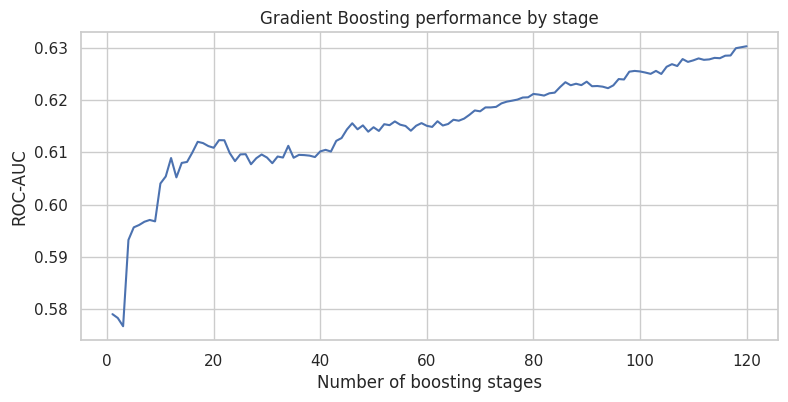

In [8]:
stage_scores = []
for stage_number, stage_pred in enumerate(gb_model.staged_predict_proba(X_test), start=1):
    stage_scores.append((stage_number, roc_auc_score(y_test, stage_pred[:, 1])))

stage_df = pd.DataFrame(stage_scores, columns=["n_estimators", "test_roc_auc"])
plt.figure(figsize=(9, 4))
plt.plot(stage_df["n_estimators"], stage_df["test_roc_auc"])
plt.xlabel("Number of boosting stages")
plt.ylabel("ROC-AUC")
plt.title("Gradient Boosting performance by stage")
plt.show()

**Teaching note:** This plot uses the test set only to demonstrate staged behavior. In a production workflow, choose the number of stages using a validation set or cross-validation, then evaluate once on the held-out test set.

## 8. XGBoost: an optimized gradient boosting library

**XGBoost** is an optimized implementation of gradient-boosted decision trees. It became widely used because it combines regularization, efficient tree construction and practical training features.

Core ideas include:

- Additive boosting: trees are added sequentially.
- Regularization: penalize overly complex trees and leaf weights.
- Gradient and second-order information: use derivatives of the loss to guide optimization.
- Efficient computation: provide optimized data structures and tree-building methods.
- Missing-value handling: learn default directions for missing values in tree splits.

XGBoost is not a different learning principle from Gradient Boosting; it is a highly engineered implementation with additional algorithmic and systems optimizations.

### Key XGBoost parameters

| Parameter | Purpose |
|---|---|
| `n_estimators` | Maximum number of boosting rounds |
| `learning_rate` (`eta`) | Shrinks each boosting step |
| `max_depth` | Maximum depth of each tree |
| `min_child_weight` | Minimum sum of instance weight needed in a child |
| `subsample` | Fraction of rows sampled per boosting round |
| `colsample_bytree` | Fraction of features sampled per tree |
| `gamma` | Minimum loss reduction required for a split |
| `reg_lambda` | L2 regularization on leaf weights |
| `reg_alpha` | L1 regularization on leaf weights |
| `scale_pos_weight` | Class-weighting control often considered for imbalanced data |

Tune a small number of parameters at a time. Large search spaces can be expensive and make results harder to interpret.

### Train an XGBoost baseline

We use the same training and test partitions as the scikit-learn model. `eval_metric` is set explicitly, and a fixed random state supports reproducibility.

In [9]:
xgb_model = XGBClassifier(
    n_estimators=250,
    learning_rate=0.04,
    max_depth=3,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost baseline")
print("Accuracy :", round(accuracy_score(y_test, xgb_pred), 3))
print("Precision:", round(precision_score(y_test, xgb_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, xgb_pred, zero_division=0), 3))
print("F1       :", round(f1_score(y_test, xgb_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, xgb_proba), 3))

XGBoost baseline
Accuracy : 0.696
Precision: 0.469
Recall   : 0.161
F1       : 0.24
ROC-AUC  : 0.631


### What does `binary:logistic` mean?

The objective `binary:logistic` is designed for binary classification. It trains the model to produce probabilities between 0 and 1. A default classification threshold is then used by `predict()` to assign a class.

A probability is not a decision by itself. The threshold should be selected according to the costs of false positives and false negatives and the available operational capacity.

### Exercise 3 — Parameter investigation

Train three XGBoost models while changing only `max_depth`:

- Model A: `max_depth=2`
- Model B: `max_depth=4`
- Model C: `max_depth=6`

Keep all other parameters fixed. Compare validation ROC-AUC and F1. Explain how tree depth affects model flexibility and overfitting risk.

## 9. Model comparison using cross-validation

A single validation split can produce a result that depends on how the data was divided. Stratified cross-validation evaluates the model over several folds while preserving class proportions.

We compare Gradient Boosting and XGBoost using the training set only. The test set is not used for model selection.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        min_samples_leaf=12, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, learning_rate=0.04, max_depth=3,
        min_child_weight=3, subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2.0, objective="binary:logistic",
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
    )
}

cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
        n_jobs=-1
    )
    cv_rows.append({
        "model": name,
        "mean_roc_auc": scores["test_roc_auc"].mean(),
        "std_roc_auc": scores["test_roc_auc"].std(),
        "mean_f1": scores["test_f1"].mean(),
        "mean_recall": scores["test_recall"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("mean_roc_auc", ascending=False)
cv_results

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,model,mean_roc_auc,std_roc_auc,mean_f1,mean_recall
1,XGBoost,0.678847,0.020566,0.301810,0.211945
0,Gradient Boosting,0.673826,0.010091,0.244405,0.157635


### Read the cross-validation results

The mean score summarizes performance across folds. The standard deviation provides information about variation between folds.

A model with a slightly higher mean score but much larger variation may be less stable. Consider the full set of metrics and the business cost of errors rather than selecting a model from one number alone.

## 10. Hyperparameter tuning with GridSearchCV

Grid search evaluates a defined set of parameter combinations using cross-validation. It is useful for a focused search, but large grids can require substantial computation.

We use a compact grid to keep the exercise practical.

In [11]:
xgb_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=1
    ),
    param_grid={
        "n_estimators": [150, 250],
        "max_depth": [2, 3],
        "learning_rate": [0.03, 0.07],
        "min_child_weight": [2, 4]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

xgb_search.fit(X_train, y_train)
print("Best parameters:", xgb_search.best_params_)
print("Best mean CV ROC-AUC:", round(xgb_search.best_score_, 3))
best_xgb = xgb_search.best_estimator_

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'learning_rate': 0.07, 'max_depth': 2, 'min_child_weight': 4, 'n_estimators': 150}
Best mean CV ROC-AUC: 0.679


### Final evaluation on the held-out test set

Only after model selection do we evaluate the selected estimator on the test set. This provides an estimate of performance on unseen data.

In [12]:
best_pred = best_xgb.predict(X_test)
best_proba = best_xgb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, best_pred, target_names=["Normal risk", "High risk"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, best_proba), 3))

              precision    recall  f1-score   support

 Normal risk       0.72      0.94      0.81       337
   High risk       0.47      0.13      0.21       143

    accuracy                           0.70       480
   macro avg       0.60      0.54      0.51       480
weighted avg       0.65      0.70      0.63       480

Test ROC-AUC: 0.637


## 11. Evaluate the selected model

A confusion matrix makes the types of classification errors visible. Rows represent actual classes and columns represent predicted classes.

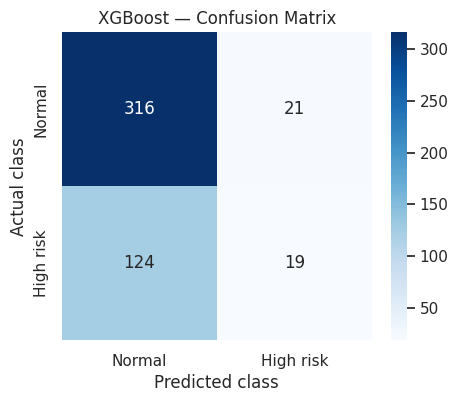

In [13]:
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"]
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("XGBoost — Confusion Matrix")
plt.show()

### ROC and Precision-Recall curves

The ROC curve shows the trade-off between true positive rate and false positive rate across thresholds. The Precision-Recall curve focuses on precision and recall, which can be especially informative when the positive class is relatively uncommon.

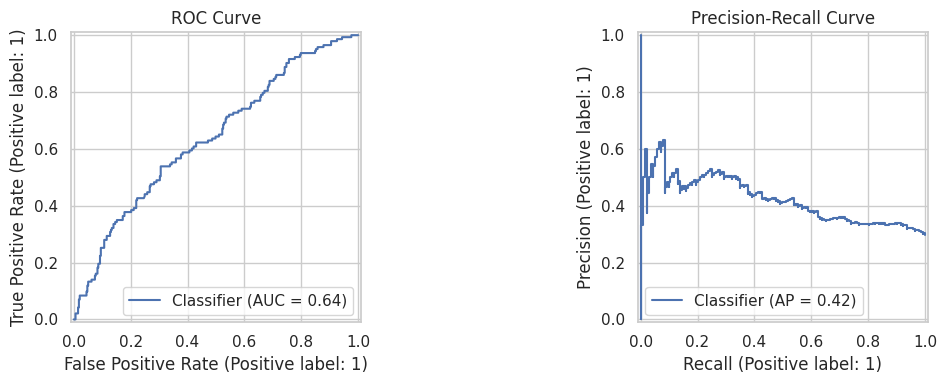

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, best_proba, ax=axes[0])
axes[0].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, best_proba, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## 12. Feature importance and model interpretation

Tree-based models provide feature-importance measures. These can help identify which features the fitted model used most strongly.

However, feature importance is not proof of causation. Correlated features can share or distort importance, and impurity-based importance can favor features with more possible split points.

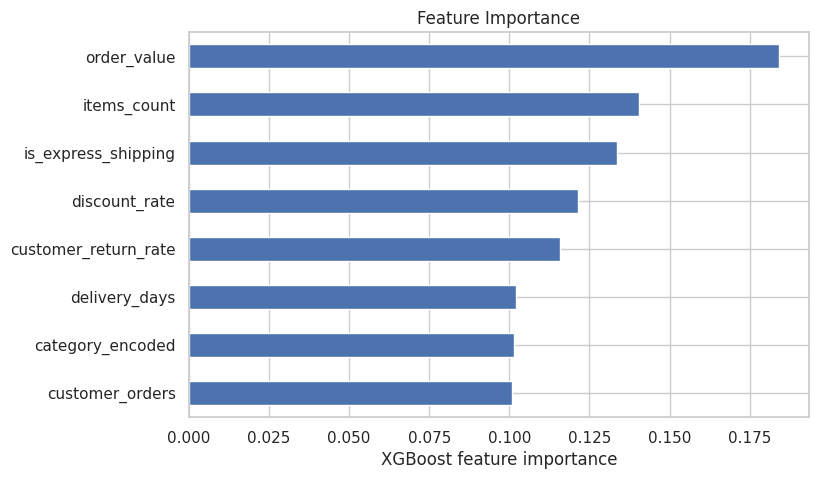

In [15]:
importance = pd.Series(
    best_xgb.feature_importances_, index=FEATURES
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.xlabel("XGBoost feature importance")
plt.title("Feature Importance")
plt.show()

### Permutation importance

Permutation importance measures how much a chosen evaluation score decreases when one feature is randomly shuffled. It can be computed on held-out data and is model-agnostic.

A large decrease suggests that the model relies on that feature for the selected metric. The result still describes model reliance, not a causal effect.

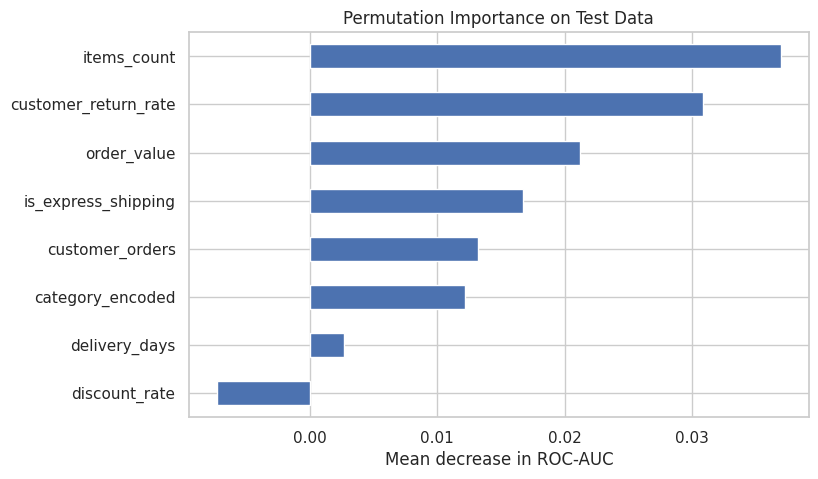

In [16]:
perm = permutation_importance(
    best_xgb, X_test, y_test,
    scoring="roc_auc", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1
)
perm_importance = pd.Series(
    perm.importances_mean, index=FEATURES
).sort_values()

plt.figure(figsize=(8, 5))
perm_importance.plot(kind="barh")
plt.xlabel("Mean decrease in ROC-AUC")
plt.title("Permutation Importance on Test Data")
plt.show()

## 13. Threshold selection and operational trade-offs

The default threshold for binary classification is commonly 0.5. In a business workflow, a different threshold may be more appropriate.

- Lower threshold: usually flags more orders, increasing recall and often increasing false positives.
- Higher threshold: usually flags fewer orders, increasing precision in some settings but potentially missing more high-risk orders.

Choose thresholds using validation data and a documented business cost or capacity constraint. Do not select a threshold by repeatedly optimizing against the test set.

In [17]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_rows = []

for threshold in thresholds:
    pred_at_threshold = (best_xgb.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "f1": f1_score(y_test, pred_at_threshold, zero_division=0),
        "flagged_orders": int(pred_at_threshold.sum())
    })

pd.DataFrame(threshold_rows).round(3)

,threshold,precision,recall,f1,flagged_orders
0,0.3,0.392,0.573,0.466,209
1,0.4,0.495,0.322,0.390,93
2,0.5,0.475,0.133,0.208,40
3,0.6,0.538,0.049,0.090,13
4,0.7,0.000,0.000,0.000,1


## 14. Mini Project — AdventureWorks Return-Risk Model Selection

### Business brief

The Operations Director wants a model that helps the team prioritize orders for manual review before fulfillment. Your task is to compare Gradient Boosting and XGBoost, select a suitable model and present a short recommendation.

### Requirements

**Part 1 — Data understanding**
1. Inspect the dataset and target distribution.
2. Explain why each feature could be useful.
3. Identify any feature that could create leakage if collected after the return event.

**Part 2 — Modeling**
1. Train a Gradient Boosting baseline.
2. Train an XGBoost baseline.
3. Use stratified cross-validation on the training set.
4. Tune at least two XGBoost parameters using a compact search.

**Part 3 — Evaluation**
1. Evaluate the selected model once on the test set.
2. Report precision, recall, F1-score and ROC-AUC.
3. Show the confusion matrix and at least one diagnostic curve.
4. Compare the selected model against a simple baseline.

**Part 4 — Interpretation**
1. Show feature importance.
2. Explain why importance does not imply causation.
3. Discuss the impact of changing the classification threshold.

**Part 5 — Recommendation**
Write a short executive recommendation that states:
- Which model you recommend and why.
- Which metric matters most for the proposed workflow.
- What operational risks remain.
- What additional data or monitoring would be needed before deployment.

### Deliverable

Submit the notebook with completed code, outputs, charts and a one-page business recommendation.

### Mini Project — Baseline comparison

Use a DummyClassifier as a simple reference point. A complex model should demonstrate value beyond a trivial prediction strategy.

In [18]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

baseline_summary = pd.DataFrame([
    {
        "model": "Dummy baseline",
        "accuracy": accuracy_score(y_test, dummy_pred),
        "precision": precision_score(y_test, dummy_pred, zero_division=0),
        "recall": recall_score(y_test, dummy_pred, zero_division=0),
        "f1": f1_score(y_test, dummy_pred, zero_division=0),
        "roc_auc": 0.5
    },
    {
        "model": "Tuned XGBoost",
        "accuracy": accuracy_score(y_test, best_pred),
        "precision": precision_score(y_test, best_pred, zero_division=0),
        "recall": recall_score(y_test, best_pred, zero_division=0),
        "f1": f1_score(y_test, best_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, best_proba)
    }
])
baseline_summary.round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Dummy baseline,0.702,0.000,0.000,0.000,0.500
1,Tuned XGBoost,0.698,0.475,0.133,0.208,0.637


## 15. Knowledge check

1. How does boosting differ from bagging?
2. Why are trees in Gradient Boosting added sequentially?
3. What is the effect of reducing `learning_rate` while keeping `n_estimators` fixed?
4. Why can increasing `max_depth` increase overfitting risk?
5. Name two regularization-related XGBoost parameters.
6. Why should hyperparameter tuning use cross-validation on the training set?
7. Why should the test set remain untouched during model selection?
8. Why is feature importance not evidence of causation?
9. What operational trade-off can occur when the classification threshold is lowered?
10. Why should a boosting model be compared with a simple baseline?

## 16. Instructor answer guide

1. Bagging trains models independently and aggregates them; boosting adds learners sequentially to improve the current ensemble.
2. Each new tree is fitted to gradient information from the current loss, helping reduce the remaining error.
3. Each tree contributes less; more estimators may be needed to reach a similar level of fit.
4. Deeper trees can learn more complex patterns, including noise and sample-specific details.
5. Examples include `reg_alpha`, `reg_lambda`, `gamma` and `min_child_weight`.
6. Cross-validation gives a more reliable estimate across multiple training folds.
7. Repeatedly using the test set for decisions leaks information about it into the modeling process.
8. Importance measures model reliance or split usage, not cause-and-effect relationships.
9. More orders may be flagged; recall may rise while precision may fall, increasing review workload.
10. A baseline shows whether the complexity of the trained model provides meaningful improvement.

## 17. Key takeaways

- Gradient Boosting builds an ensemble by adding trees sequentially.
- Learning rate, number of estimators and tree complexity must be considered together.
- XGBoost extends gradient-boosted trees with regularization and computational optimizations.
- Cross-validation supports model selection; a held-out test set supports final evaluation.
- Metrics and thresholds should reflect the business cost of different errors.
- Feature importance helps describe model behavior but does not establish causality.
- A model is not ready for deployment without data-quality checks, monitoring, governance and operational validation.

### Readiness checklist

Before moving to the next topic, confirm that you can:

- [ ] Explain the boosting process without relying on code.
- [ ] Train a Gradient Boosting classifier.
- [ ] Explain the main XGBoost parameters.
- [ ] Tune a model using cross-validation.
- [ ] Evaluate a classifier with multiple metrics.
- [ ] Interpret feature importance carefully.
- [ ] Explain why the test set must remain separate.
- [ ] Present a model recommendation in business terms.

**Next step:** Apply the same disciplined workflow to the next model family, keeping data preparation, validation and business interpretation central to every experiment.